# Gonza: química y hamiltoniano de H₄

Valida `src/hamiltonian.py`, grafica la referencia (HF, CCSD, FCI) y analiza los coeficientes del hamiltoniano. Se corre desde la raíz del repo o desde `notebooks/`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd())
import numpy as np
import matplotlib.pyplot as plt
from src.hamiltonian import DISTANCES, build_problem, validate_problem
problemas = {d: build_problem(d) for d in DISTANCES}
print(len(DISTANCES), 'distancias:', DISTANCES)

15 distancias: [0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.4, 2.7, 3.0]


## 1. Validación contra FCI

El autovalor más chico de `hamiltonian.to_matrix()` en el sector N=4, S²=0 tiene que coincidir con el FCI de PySCF hasta 1e-8. Además verificamos que el estado de HF en qubits da la energía de HF de PySCF (esto confirma que la repulsión nuclear está incluida y que el bitstring es correcto).

In [2]:
print(f"{'d':>5} {'E_min - E_FCI':>14} {'<N>':>8} {'<S2>':>10} {'E_HF(qubits)-E_HF':>18}")
for d, p in problemas.items():
    r = validate_problem(p)
    assert r['error'] < 1e-8, (d, r)
    assert abs(r['N'] - 4) < 1e-8 and abs(r['S2']) < 1e-8
    assert abs(r['e_hf_check'] - p['e_hf']) < 1e-8
    print(f"{d:5.2f} {r['error']:14.2e} {r['N']:8.4f} {r['S2']:10.1e} {r['e_hf_check']-p['e_hf']:18.1e}")
print('Todo valida: error < 1e-8 en las', len(DISTANCES), 'distancias.')
print('hf_bitstring =', problemas[1.0]['hf_bitstring'], '| n_qubits =', problemas[1.0]['n_qubits'])
print('t1:', problemas[1.0]['ccsd_t1'].shape, ' t2:', problemas[1.0]['ccsd_t2'].shape)

    d  E_min - E_FCI      <N>       <S2>  E_HF(qubits)-E_HF
 0.60       4.44e-16   4.0000   -1.4e-19            2.4e-15
 0.70       3.55e-15   4.0000    6.5e-31            0.0e+00
 0.80       3.55e-15   4.0000    2.8e-19           -2.2e-15
 0.90       8.88e-16   4.0000    3.8e-19           -1.3e-15
 1.00       4.44e-15   4.0000   -4.2e-19            2.2e-15
 1.10       4.00e-15   4.0000    6.1e-19           -1.3e-15
 1.20       3.11e-15   4.0000   -5.2e-19            1.8e-15
 1.40       5.77e-15   4.0000    3.0e-18            6.0e-15
 1.60       4.66e-15   4.0000   -5.4e-18           -3.6e-15
 1.80       1.11e-15   4.0000    4.1e-31            6.7e-16
 2.00       4.44e-15   4.0000    6.9e-31           -4.9e-15
 2.20       3.33e-15   4.0000    2.6e-17            2.2e-15
 2.40       6.66e-16   4.0000    1.0e-30           -8.9e-16
 2.70       3.11e-15   4.0000    4.6e-31           -3.1e-15
 3.00       3.11e-15   4.0000    1.6e-31           -3.3e-15
Todo valida: error < 1e-8 en las 15 dist

## 2. Curvas de referencia y cuánto hay que ganarle a CCSD

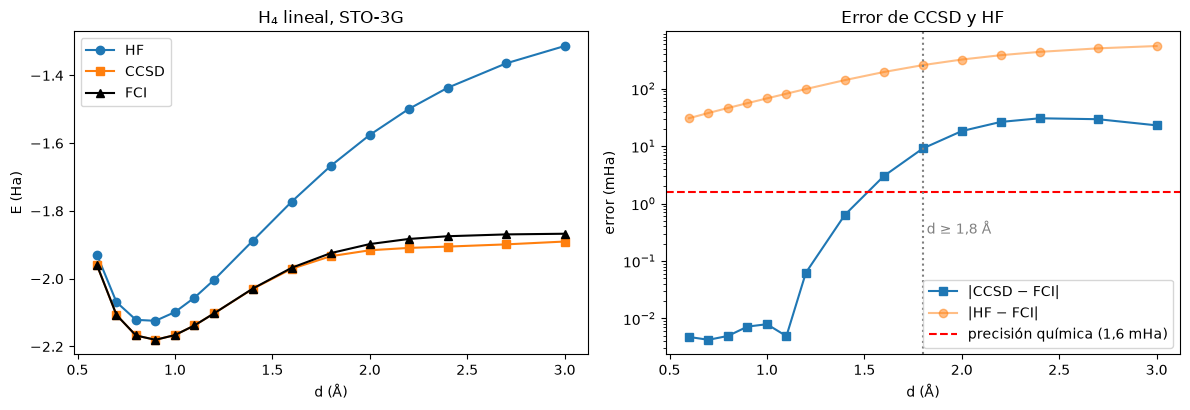

 d (Å)   E_FCI (Ha)  |CCSD−FCI| (mHa)  |HF−FCI| (mHa)
  0.60    -1.960194             0.005            30.6
  0.70    -2.106997             0.004            37.8
  0.80    -2.167561             0.005            46.2
  0.90    -2.180317             0.007            56.1
  1.00    -2.166387             0.008            67.8
  1.10    -2.137971             0.005            81.9
  1.20    -2.102608             0.063            98.7
  1.40    -2.029070             0.636           141.3
  1.60    -1.967560             3.012           195.4
  1.80    -1.924431             9.108           257.6
  2.00    -1.897781            18.305           322.2
  2.20    -1.882713            26.408           383.6
  2.40    -1.874652            30.560           438.2
  2.70    -1.869231            29.446           504.8
  3.00    -1.867291            23.013           554.0


In [3]:
d = np.array(DISTANCES)
e_hf  = np.array([problemas[x]['e_hf']   for x in DISTANCES])
e_cc  = np.array([problemas[x]['e_ccsd'] for x in DISTANCES])
e_fci = np.array([problemas[x]['e_fci']  for x in DISTANCES])
err_cc_mHa = 1000*np.abs(e_cc - e_fci)   # CCSD no es variacional: pasa por debajo del FCI al estirar
err_hf_mHa = 1000*np.abs(e_hf - e_fci)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(d, e_hf, 'o-', label='HF'); ax[0].plot(d, e_cc, 's-', label='CCSD'); ax[0].plot(d, e_fci, 'k^-', label='FCI')
ax[0].set_xlabel('d (Å)'); ax[0].set_ylabel('E (Ha)'); ax[0].set_title('H₄ lineal, STO-3G'); ax[0].legend()
ax[1].semilogy(d, err_cc_mHa, 's-', label='|CCSD − FCI|')
ax[1].semilogy(d, err_hf_mHa, 'o-', label='|HF − FCI|', alpha=.5)
ax[1].axhline(1.6, color='r', ls='--', label='precisión química (1,6 mHa)')
ax[1].axvline(1.8, color='gray', ls=':'); ax[1].text(1.82, 0.3, 'd ≥ 1,8 Å', color='gray')
ax[1].set_xlabel('d (Å)'); ax[1].set_ylabel('error (mHa)'); ax[1].set_title('Error de CCSD y HF'); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"{'d (Å)':>6} {'E_FCI (Ha)':>12} {'|CCSD−FCI| (mHa)':>17} {'|HF−FCI| (mHa)':>15}")
for x, a, b, c in zip(d, e_fci, err_cc_mHa, err_hf_mHa):
    print(f"{x:6.2f} {a:12.6f} {b:17.3f} {c:15.1f}")

Distancia de equilibrio y energía de disociación según FCI, como **referencia** para validar lo que salga del VQE (escaneo fino solo con FCI; la grilla de arriba es la que se usa para VQE).

In [4]:
from scipy.optimize import minimize_scalar
from pyscf import gto, scf, mcscf
from src.hamiltonian import geometria
def e_fci_de(x):
    mol = gto.M(atom=geometria(x), basis='sto-3g', verbose=0)
    hf = scf.RHF(mol).run(); return mcscf.CASCI(hf, 4, 4).kernel()[0]
r = minimize_scalar(e_fci_de, bounds=(0.7, 1.4), method='bounded', options={'xatol': 1e-6})
Re, E_Re = r.x, r.fun
print(f"R_e (FCI) = {Re:.4f} Å,  E(R_e) = {E_Re:.8f} Ha")
print(f"D_e (FCI) = E(3,0 Å) − E(R_e) = {e_fci[-1]-E_Re:.6f} Ha = {1000*(e_fci[-1]-E_Re):.2f} mHa")
print('Puntos de la grilla más cercanos a R_e:', [x for x in DISTANCES if abs(x-Re) < 0.25])

R_e (FCI) = 0.8882 Å,  E(R_e) = -2.18050559 Ha
D_e (FCI) = E(3,0 Å) − E(R_e) = 0.313214 Ha = 313.21 mHa
Puntos de la grilla más cercanos a R_e: [0.7, 0.8, 0.9, 1.0, 1.1]


## 3. Estructura del hamiltoniano (para repartir shots)

Cuántos términos de Pauli hay, cuántos grupos conmutan (qubit-wise) y cómo se distribuyen los $|c_k|$. Se la pasa a Maxi.

In [5]:
print(f"{'d':>5} {'términos':>9} {'sin identidad':>14} {'grupos QWC':>11} {'Σ|c_k| (sin I)':>15}")
filas = []
for x, p in problemas.items():
    H = p['hamiltonian']
    sin_id = H[[not set(l) <= {'I'} for l in H.paulis.to_labels()]]
    grupos = sin_id.group_commuting(qubit_wise=True)
    filas.append((x, len(H), len(sin_id), len(grupos), np.abs(sin_id.coeffs).sum()))
    print(f"{x:5.2f} {len(H):9d} {len(sin_id):14d} {len(grupos):11d} {np.abs(sin_id.coeffs).sum():15.3f}")

    d  términos  sin identidad  grupos QWC  Σ|c_k| (sin I)
 0.60       185            184          46          10.253
 0.70       185            184          46           9.115
 0.80       185            184          46           8.294
 0.90       185            184          46           7.657
 1.00       185            184          46           7.145
 1.10       185            184          46           6.726
 1.20       185            184          46           6.391
 1.40       185            184          46           5.865
 1.60       185            184          46           5.472
 1.80       185            184          46           5.211
 2.00       185            184          46           4.997
 2.20       185            184          46           4.816
 2.40       185            184          46           4.704
 2.70       185            184          46           4.534
 3.00       185            184          46           4.367


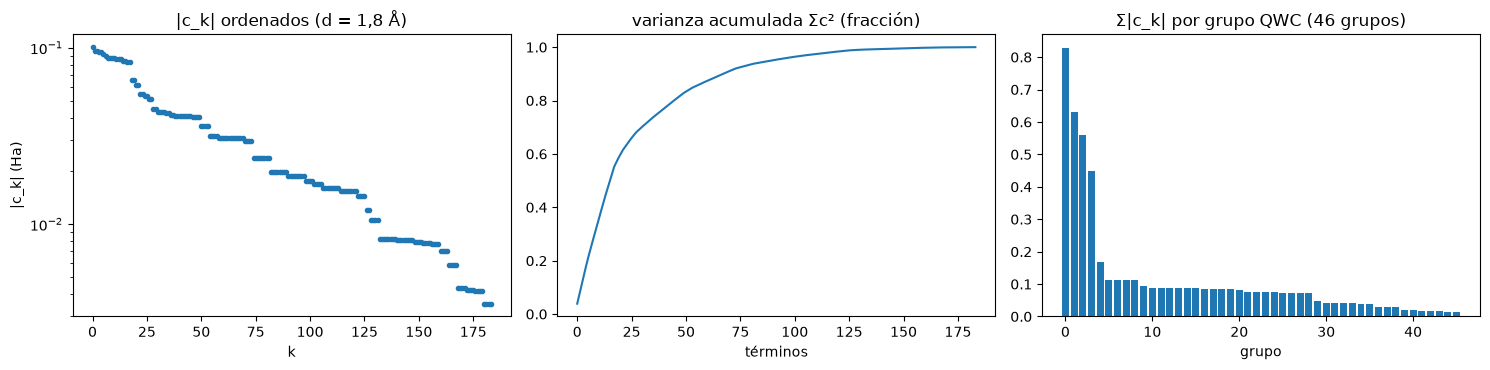

Términos: 185 (1 identidad + 184), grupos QWC: 46
Coef. más grande (sin I): 0.1007 Ha; mediana: 0.0188; mínimo: 3.54e-03
El 90% de Σc² está en 68 términos
Tamaño de los grupos: [14, 11, 11, 8, 6, 6, 6, 6, 6, 5, 5, 5, 5, 5, 5, 4, 4, 4, 4, 4, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1]


In [6]:
p = problemas[1.8]; H = p['hamiltonian']
mask = np.array([not set(l) <= {'I'} for l in H.paulis.to_labels()])
c = np.abs(H.coeffs[mask]); c_ord = np.sort(c)[::-1]
grupos = H[mask].group_commuting(qubit_wise=True)
pesos = np.array([np.abs(g.coeffs).sum() for g in grupos])

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].semilogy(c_ord, '.'); ax[0].set_title('|c_k| ordenados (d = 1,8 Å)'); ax[0].set_xlabel('k'); ax[0].set_ylabel('|c_k| (Ha)')
ax[1].plot(np.cumsum(c_ord**2)/np.sum(c_ord**2)); ax[1].set_title('varianza acumulada Σc² (fracción)'); ax[1].set_xlabel('términos'); 
ax[2].bar(range(len(pesos)), np.sort(pesos)[::-1]); ax[2].set_title(f'Σ|c_k| por grupo QWC ({len(grupos)} grupos)'); ax[2].set_xlabel('grupo')
plt.tight_layout(); plt.show()
print(f"Términos: {len(H)} (1 identidad + {mask.sum()}), grupos QWC: {len(grupos)}")
print(f"Coef. más grande (sin I): {c_ord[0]:.4f} Ha; mediana: {np.median(c):.4f}; mínimo: {c_ord[-1]:.2e}")
print(f"El 90% de Σc² está en {np.searchsorted(np.cumsum(c_ord**2)/np.sum(c_ord**2), 0.9)+1} términos")
print('Tamaño de los grupos:', sorted(len(g) for g in grupos)[::-1])

## Resumen para el equipo

- `build_problem(d)` valida contra FCI (error < 1e-8 en toda la grilla), con N = 4 y S² = 0 en el estado fundamental.
- Convención: 8 qubits, Jordan-Wigner, alfa en los qubits 0–3 y beta en 4–7 (como el workshop y `qiskit-nature`); HF = `"00110011"`.
- El hamiltoniano ya incluye la repulsión nuclear.
- CCSD no es variacional: a partir de ~1,1 Å queda **por debajo** del FCI. El error a superar es $|E_\text{CCSD}-E_\text{FCI}|$: ~9 mHa en 1,8 Å, máximo de ~31 mHa cerca de 2,4 Å y ~23 mHa en 3,0 Å.
- `ccsd_t1` / `ccsd_t2` están en orbitales espaciales (RHF), sin expandir a spin-orbitales.